# 第八课：现金收益改变了多少结论？

第六、七课研究了退出风险资产和降低敞口，但现金始终零利息。本课把现金收益加入同一个可对账账户，检查比较结果对这一假设的敏感性。

**学习目标**：区分年化利率与实际收益；按正确本金和时间计息；区分参考利率与可获得收益；认识研究结果和前瞻证据的边界。

本课保持ETF行情、风险与趋势规则、交易成本不变，不为任何策略寻找有利参数。仍处于第二阶段“信号验证”，新增的是账户现实性，不是更复杂的预测模型。

## 1. 真实利率从哪里来，能不能直接拿到？

使用 [FRED DFF](https://fred.stlouisfed.org/series/DFF)：历史联邦基金有效利率，原单位为百分数、年化。它描述银行间市场，不是ETF总回报，也不是个人账户自动获得的现金利率。

[纽约联储](https://www.newyorkfed.org/markets/reference-rates/effr)说明EFFR通常次一营业日发布前一营业日数据。因此不能把观测日期直接当作可得日期。本课为清楚且保守，取每段计息开始前**至少7个日历日**的最近观测，记录所用日期；不把这个人为滞后称为真实发布档案。下载的历史也可能经过修订。

固定比较三种现金情景：零利息、滞后参考利率、参考利率减100bps并以零为下限。100bps=1个百分点，是教学折扣，不对应真实券商报价。现金分层门槛、税费和货币基金等不同实现留待以后研究。

ETF快照： 20261007T234808781424Z ；利率快照： dff_c7cffd0a8f824826
比较区间： 2011-02-01 至 2026-10-06
利率原始覆盖： 2010-01-01 至 2026-10-06


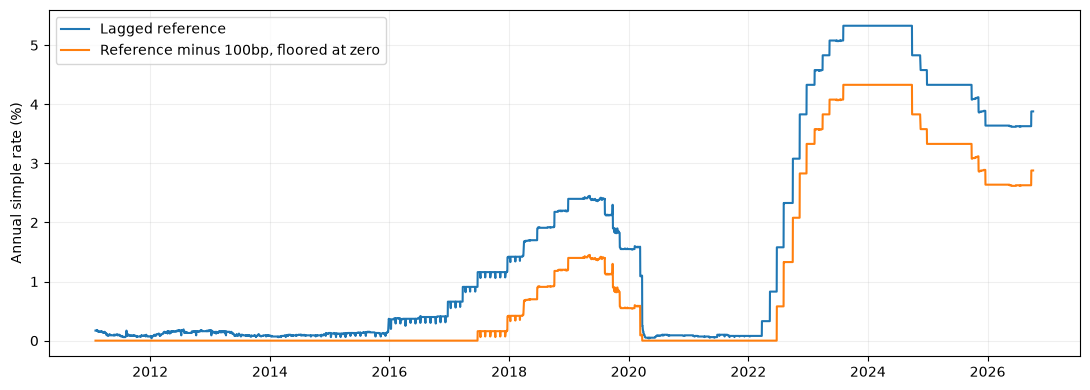

,period_start,observation_date,assumed_available_date,days,annual_rate
date,,,,,
2011-02-01,2011-02-01,2011-01-25,2011-02-01,0,0.0017
2011-02-02,2011-02-01,2011-01-25,2011-02-01,1,0.0017
2011-02-03,2011-02-02,2011-01-26,2011-02-02,1,0.0017
2011-02-04,2011-02-03,2011-01-27,2011-02-03,1,0.0017


In [1]:
from pathlib import Path
import os,sys,json,hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display,Markdown
ROOT=Path.cwd()
if not (ROOT/'src').exists():ROOT=ROOT.parent
sys.path.insert(0,str(ROOT/'src'))
from market_data import load_snapshot
from cash_rates import load_rates,rate_schedule
from risk_models import equal_risk_schedule
from signals import trend_filter_schedule
from controls import scale_schedule
from portfolio import simulate,reconcile
SNAPSHOT=os.environ.get('MARKET_LAB_SNAPSHOT','20261007T234808781424Z')
RATE_SNAPSHOT=os.environ.get('MARKET_LAB_RATE_SNAPSHOT','dff_c7cffd0a8f824826')
frames,manifest=load_snapshot(SNAPSHOT);rates,rate_manifest=load_rates(RATE_SNAPSHOT)
prices=pd.DataFrame({s:f['Adj Close'] for s,f in frames.items()});assets=list(prices.columns)
base,_=equal_risk_schedule(prices,126)
base=base.loc[[d for d in base.index if prices.index.get_loc(d)>=253]].copy()
trend,_=trend_filter_schedule(prices,base,200)
schedules={'erc_126':base,'trend_200':trend,'fixed_70':scale_schedule(base,assets,.7),
           'dynamic_total':scale_schedule(base,assets,trend[assets].sum(axis=1))}
START=base.index[0];trading={s:f.loc[START:].copy() for s,f in frames.items()};dates=trading['SPY'].index
reference=rate_schedule(rates,dates,lag_days=7)
discount=rate_schedule(rates,dates,lag_days=7,spread_bps=100)
scenarios={'zero':None,'reference':reference,'minus_100bp':discount}
OUT=ROOT/'reports'/('08_'+SNAPSHOT+'_'+rate_manifest['snapshot']);OUT.mkdir(parents=True,exist_ok=True)
plt.rcParams.update({'figure.figsize':(11,4),'axes.grid':True,'grid.alpha':.2})
print('ETF快照：',SNAPSHOT,'；利率快照：',rate_manifest['snapshot'])
print('比较区间：',START.date(),'至',dates[-1].date())
print('利率原始覆盖：',rate_manifest['first_date'],'至',rate_manifest['last_date'])
fig,ax=plt.subplots()
ax.plot(dates,reference.annual_rate*100,label='Lagged reference')
ax.plot(dates,discount.annual_rate*100,label='Reference minus 100bp, floored at zero')
ax.set_ylabel('Annual simple rate (%)');ax.legend();fig.tight_layout();fig.savefig(OUT/'rates.png',dpi=150);plt.show()
display(reference[['period_start','observation_date','assumed_available_date','days','annual_rate']].head(4))
reference.to_csv(OUT/'reference_rate_audit.csv');discount.to_csv(OUT/'discount_rate_audit.csv')

## 2. 年化利率如何变成账上的钱？

本课使用简单ACT/360：**利息＝上一收盘现金 × 年化利率 × 实际日历天数÷360**。

例如周五收盘有10,000美元现金，假设年化3.6%，周一入账利息为10,000×0.036×3/360＝3美元。不是只算一个交易日，也不是把3.6%每天加一次。

每段利率在开始时确定并保持到下一观察日；周末内部不逐日复利，下一次入账后可以复利。先入账利息，再处理今天的分红和交易；今天卖出所得和今天分红不能倒过来赚昨天的利息。首日没有持有历史，不计息。

这是教学现金账户模型，不是国库券购买、货币基金价格收益或真实券商月度付息的精确复制。利息可以在当日计划调仓中再投入，随后持仓和费用也可能变化。

In [2]:
results={};rows=[]
for scenario,table in scenarios.items():
    for policy,s in schedules.items():
        r=simulate(trading,s.iloc[0][assets].to_dict(),target_schedule=s,cash_rates=table)
        reconcile(r);results[(scenario,policy)]=r
        rows.append(dict(scenario=scenario,policy=policy,**r.metrics().to_dict(),
                         mean_cash=float((r.daily.cash/r.daily.nav).mean())))
metrics=pd.DataFrame(rows).set_index(['scenario','policy']);metrics.to_csv(OUT/'metrics.csv')
for scenario in scenarios:
    print('现金情景：',scenario)
    display(metrics.loc[scenario,['cagr','annual_volatility','max_drawdown','mean_cash']].style.format('{:.2%}'))
print('列：年化收益／年化波动／最大回撤／日均现金。所有情景使用相同目标规则。')
comparison=metrics[['final_nav','fees_paid','interest_received']].copy()
comparison['nav_gain_vs_zero']=[metrics.loc[(scenario,policy),'final_nav']-metrics.loc[('zero',policy),'final_nav']
    for scenario,policy in comparison.index]
display(comparison.style.format('{:,.2f}'));comparison.to_csv(OUT/'interest_and_nav.csv')
print('利息总额不一定等于期末净值增量：利息再投入后的盈亏、现金和费用路径也会改变。')

现金情景： zero


,cagr,annual_volatility,max_drawdown,mean_cash
policy,,,,
erc_126,6.28%,6.35%,-17.89%,0.02%
trend_200,4.72%,4.85%,-10.86%,29.60%
fixed_70,4.40%,4.44%,-12.80%,29.97%
dynamic_total,4.78%,4.53%,-10.62%,29.61%


现金情景： reference


,cagr,annual_volatility,max_drawdown,mean_cash
policy,,,,
erc_126,6.28%,6.35%,-17.89%,0.02%
trend_200,5.17%,4.85%,-9.25%,29.61%
fixed_70,4.91%,4.44%,-12.57%,29.99%
dynamic_total,5.23%,4.53%,-8.97%,29.62%


现金情景： minus_100bp


,cagr,annual_volatility,max_drawdown,mean_cash
policy,,,,
erc_126,6.28%,6.35%,-17.89%,0.02%
trend_200,4.99%,4.85%,-9.88%,29.61%
fixed_70,4.74%,4.44%,-12.70%,29.98%
dynamic_total,5.06%,4.53%,-9.64%,29.61%


列：年化收益／年化波动／最大回撤／日均现金。所有情景使用相同目标规则。


利息总额不一定等于期末净值增量：利息再投入后的盈亏、现金和费用路径也会改变。


## 3. 看收益提升，也检查排名与回撤

下面使用“参考利率减100bps”作为一张便于阅读的情景图，不把它称为真实账户收益或最优假设。其他情景的完整结果在上表。

满仓ERC也可能收到少量现金利息，例如分红在两次调仓之间留存；高现金策略通常对利率假设更敏感。基准利率是年化输入，不能直接乘以全区间平均现金就精确得到CAGR提升。

图表和表格都保留原策略，不因新结果更换基准。零利息结果是上一课的可核对参照，计息结果是新假设下的历史模拟。

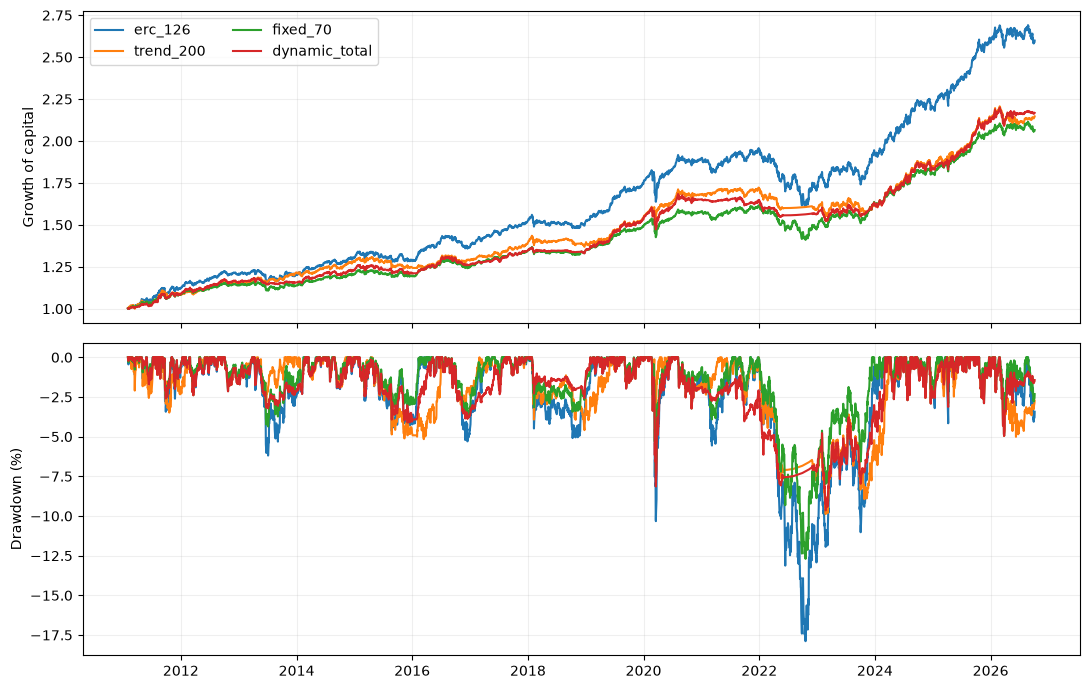

相对零现金收益，CAGR提升的百分点：


,reference,minus_100bp
policy,,
erc_126,+0.000,+0.000
trend_200,+0.448,+0.274
fixed_70,+0.510,+0.334
dynamic_total,+0.448,+0.274


全现金手算复利链与账本一致；期末金额： 118,250.81
实际多日计息事件：


,date,period_start,principal,annual_rate,days,amount
1609,2017-06-26,2017-06-23,261.715194,0.0016,3,0.003490
1614,2017-07-03,2017-06-30,261.723336,0.0016,3,0.003490
1667,2017-09-18,2017-09-15,239.323946,0.0016,3,0.003191


In [3]:
fig,axes=plt.subplots(2,1,figsize=(11,7),sharex=True)
for policy in schedules:
    r=results[('minus_100bp',policy)];nav=r.daily.nav
    peak=np.maximum.accumulate(np.r_[r.initial_cash,nav])[1:]
    axes[0].plot(nav.index,nav/r.initial_cash,label=policy)
    axes[1].plot(nav.index,(nav/peak-1)*100)
axes[0].legend(ncol=2);axes[0].set_ylabel('Growth of capital')
axes[1].set_ylabel('Drawdown (%)');fig.tight_layout();fig.savefig(OUT/'comparison.png',dpi=150);plt.show()
gains=pd.DataFrame({scenario:(metrics.loc[scenario,'cagr']-metrics.loc['zero','cagr'])*100
                    for scenario in ['reference','minus_100bp']})
print('相对零现金收益，CAGR提升的百分点：');display(gains.style.format('{:+.3f}'))
gains.to_csv(OUT/'cagr_lift_pp.csv')
# Pure cash account isolates accrual without asset P&L or trading costs.
cash_only=simulate(trading,dict.fromkeys(assets,0),cash_rates=discount)
reconcile(cash_only)
expected=100000*np.prod(1+discount.annual_rate.to_numpy()*discount.days.to_numpy()/360)
assert np.isclose(cash_only.daily.nav.iloc[-1],expected,atol=1e-6)
print('全现金手算复利链与账本一致；期末金额：',f'{expected:,.2f}')
example=results[('minus_100bp','trend_200')].interest_events
example=example[(example.days>1)&(example.amount>0)].head(3)
print('实际多日计息事件：');display(example)

## 4. 检验与限制

新增测试覆盖：百分数转小数、周末日历计息、利息再投入、卖出当天不得获得前段利息、当日分红不能提前计息、零利率兼容、缺失／过旧数据拒绝、未来利率变化不改变此前映射。每笔利息保留本金、起点、天数和利率，可独立核对。

重要边界：DFF不是可直接买入的产品；7日滞后是人为约定，不是实际发布时间；当前下载的历史不是原始历史版本。折扣、零下限、ACT/360、每观察日付息、未计税务与结算都是模型假设，不应据此承诺真实可赚到这些利息。

没有全样本参数择优；也没有因为现金计息就解决信号是否有效的问题。

In [4]:
previous=ROOT/'reports'/('07_'+SNAPSHOT)/'metrics.csv'
if previous.exists():
    old=pd.read_csv(previous,index_col=0)
    fields=['final_nav','cagr','annual_volatility','max_drawdown','fees_paid']
    np.testing.assert_allclose(metrics.loc['zero'].loc[list(schedules),fields],old.loc[list(schedules),fields],rtol=1e-10,atol=1e-7)
    print('零利息四个方案与第七课一致。')
for (scenario,policy),r in results.items():
    stem=scenario+'_'+policy
    r.daily.to_csv(OUT/(stem+'_daily.csv'));r.trades.to_csv(OUT/(stem+'_trades.csv'),index=False)
    r.interest_events.to_csv(OUT/(stem+'_interest.csv'),index=False)
settings=dict(etf_snapshot=SNAPSHOT,rate_manifest=rate_manifest,source_manifest=manifest,
    lag_calendar_days=7,spread_scenarios_bps=[0,100],floor_rate=0,day_count=360,
    timing='previous close cash; credit before current distributions and trades',
    first_day_interest=0,limitations=['proxy not investable','current-vintage rates','artificial 7-day lag','no taxes or settlement'],
    code_sha256={p:hashlib.sha256((ROOT/p).read_bytes()).hexdigest() for p in
        ['src/cash_rates.py','src/portfolio.py','notebooks/build_08.py','docs/08_research_design.md']})
(OUT/'run_manifest.json').write_text(json.dumps(settings,indent=2),encoding='utf-8')
print('12个情景账本与全现金对照均对账通过。')

零利息四个方案与第七课一致。


12个情景账本与全现金对照均对账通过。


## 5. 验证协议：下一阶段怎样避免“看答案调规则”？

新增 `docs/validation_protocol.md`，这是后续工作的约定，**还没有启动前瞻模拟或真实交易**。

开始前冻结：策略版本、参数、基准、现金与成本处理，以及评估目标和复核窗口。保存每次原始数据和在成交之前生成的决定；发生缺失或修改时如实记录。按事先规则复核完整期间，版本变化另起记录，不覆盖过去、不回填成“当时决策”。

已经看过的2011–2026历史仍是探索样本，不能换个切分日期就变成独立验证。效果不明显时保留简单基准，而不是叠加规则直至回测获胜。

### 自测

1. 现金30%、年化利率4%，能否认定组合CAGR必定增加1.2个百分点？——不能，这是粗略单期直觉；利率、现金比例、复利和再投资路径都变化。
2. 周一刚卖出股票，能否让卖出所得赚周末利息？——不能，计息本金是上一收盘现金。
3. 数据日期早于交易日，是否一定说明当时可得？——不能，还需发布时间与版本；本课只是人为滞后近似。
4. 计息后策略表现改善，是不是证明趋势有效？——不是，先说明现金处理更完整，再看合理对照与未来证据。
